In [1]:
import os, sys, mne, socket, time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from nilearn import plotting
from itertools import product

# Decoding tools
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from mne.decoding import (
    CSP,
    GeneralizingEstimator,
    LinearModel,
    Scaler,
    SlidingEstimator,
    GeneralizingEstimator,
    Vectorizer,
    cross_val_multiscore,
    get_coef,
)

from initialization import load_paths
from preprocFuncs import getRawData, getTrials, getPower, RunRSA
from plotters import plotPower, plotRSA, plotDiffRSA
from decodeHelpers import *

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
subjID = 99
day = 3
p = load_paths(subjID, day)
# Load behavioral data
master_df = pd.read_csv(os.path.join(p['meta'], 'master_df.csv'))
behav_df = master_df[(master_df['subjID'] == subjID) & (master_df['day'] == day)]
relevCols = [col for col in behav_df.columns if 'oriArray_' not in col]
behav_df = behav_df[relevCols]
# Load raw data
raw_data = getRawData(p)

# Define events
events, tah = mne.events_from_annotations(raw_data)
events_dict = {
    'BlockOnset': 1001,
    'BlockEnd': 7,
    'Fixation': 1,
    'Delay1': 2,
    'Delay2': 3,
    'Response': 4,
    'Feedback': 5,
    'ITI': 6,
}
trl_events = {
    'inPF': 11,
    'outPF': 10,
}

# Define electrodes of interest
left_occ_elecs = ['O1', 'PO3', 'PO7', 'P1', 'P3', 'P7']
right_occ_elecs = ['O2', 'PO4', 'PO8', 'P2', 'P4', 'P8']
left_par_elecs = ['P7', 'P5', 'P3', 'CP5', 'CP3', 'CP1', 'C5', 'C3', 'C1']
right_par_elecs = ['P8', 'P6', 'P4', 'CP6', 'CP4', 'CP2', 'C6', 'C4', 'C2']

left_elecs = ['O1', 'PO3', 'PO7', 'P1', 'P3', 'P7', 'P5', 'CP5', 'CP3', 'CP1', 'C5', 'C3', 'C1']
right_elecs = ['O2', 'PO4', 'PO8', 'P2', 'P4', 'P8', 'P6', 'CP6', 'CP4', 'CP2', 'C6', 'C4', 'C2']

left_occ_elecs = [elec for elec in left_occ_elecs if elec in raw_data.ch_names]
right_occ_elecs = [elec for elec in right_occ_elecs if elec in raw_data.ch_names]
left_par_elecs = [elec for elec in left_par_elecs if elec in raw_data.ch_names]
right_par_elecs = [elec for elec in right_par_elecs if elec in raw_data.ch_names]
left_elecs = [elec for elec in left_elecs if elec in raw_data.ch_names]
right_elecs = [elec for elec in right_elecs if elec in raw_data.ch_names]
# trials_list = getTrials(raw_data, events_dict, events)


Running pre-processing ...
Extracting parameters from /d/DATD/datd/TMS_ori/EEGfiles/sub99/day03/sub99_day03.vhdr...
Setting channel info structure...
Reading 0 ... 4382679  =      0.000 ...  4382.679 secs...
Used Annotations descriptions: ['Response/R  1', 'Stimulus/S  1', 'Stimulus/S  2', 'Stimulus/S  3', 'Stimulus/S  4', 'Stimulus/S  5', 'Stimulus/S  6', 'Stimulus/S  7', 'Stimulus/S 10', 'Stimulus/S 11']


In [3]:
ica_raw = mne.preprocessing.ICA(n_components=40, random_state=42, max_iter='auto', method='fastica', verbose=True)
ica_raw.fit(raw_data)
ica_raw.exclude = [0, 1]
raw_data = ica_raw.apply(raw_data)
# ica_raw.plot_components()
# ica_raw.plot_sources(raw_data)
# ica_raw.plot_properties(raw_data, picks=[0, 1])

Fitting ICA to data using 55 channels (please be patient, this may take a while)
Selecting by number: 40 components
Fitting ICA took 231.7s.
Applying ICA to Raw instance
    Transforming to ICA space (40 components)
    Zeroing out 2 ICA components
    Projecting back using 55 PCA components


In [4]:
if 'Cz' not in raw_data.ch_names:
    raw_data = raw_data.add_reference_channels(ref_channels=['Cz'])
raw_data.set_eeg_reference(ref_channels='average')

/var/folders/cf/d9j3_ppd5wb4bn9y_fgj3nb800010l/T/ipykernel_46916/3240632456.py:2: RuntimeWarning: The locations of multiple reference channels are ignored.
  raw_data = raw_data.add_reference_channels(ref_channels=['Cz'])


EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


Measurement date,Unknown
Experimenter,Unknown
Participant,Unknown
Digitized points,66 points
Good channels,56 EEG
Bad channels,None
EOG channels,Not available
ECG channels,Not available
Sampling frequency,1000.00 Hz
Highpass,0.50 Hz
Lowpass,55.00 Hz


In [ ]:
behav_df.head(10)

In [3]:
epochData = mne.Epochs(raw_data, events, event_id=trl_events, tmin=-2, tmax=4.5, baseline=None, preload=True)
epochDataBasecorr = mne.Epochs(raw_data, events, event_id=trl_events, tmin=-2, tmax=4.5, baseline=(-1, 0), preload=True)
inPF_trials = behav_df[behav_df['stimPF'] == 1].index
outPF_trials = behav_df[behav_df['stimPF'] == 0].index

Not setting metadata
312 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 312 events and 6501 original time points ...
0 bad epochs dropped
Not setting metadata
312 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 312 events and 6501 original time points ...
0 bad epochs dropped


[0 1]


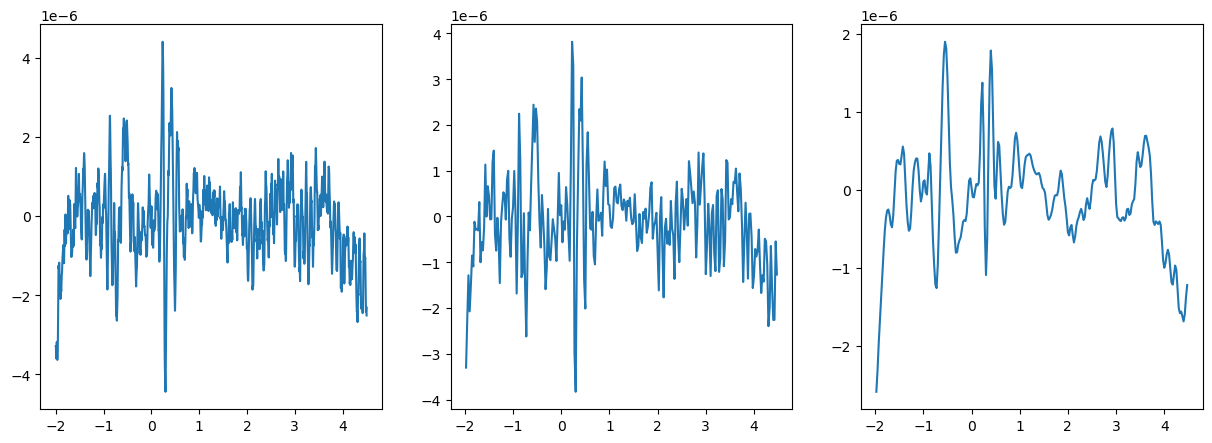

In [4]:
w_size = 1.5
down_wsize = 25
t_array = epochData.times
X = epochData.get_data(copy=True)
occ_elecs = left_occ_elecs + right_occ_elecs
occElecsIdx = [epochData.ch_names.index(elec) for elec in occ_elecs]
X = X[:, occElecsIdx, :]
y_hemi = behav_df['stimPF'].values
y_ori = behav_df['targOriCategory'].values
y_ori_cat = [0 if ori == 30 or ori == 60 else 1 for ori in y_ori]

y__ = np.empty_like(y_ori)
y__[((np.array(y_ori) == 30) | (np.array(y_ori) == 60)) & (np.array(y_hemi) == 1)] = 0
y__[((np.array(y_ori) == 30) | (np.array(y_ori) == 60)) & (np.array(y_hemi) == 0)] = 1
y__[((np.array(y_ori) == 120) | (np.array(y_ori) == 150)) & (np.array(y_hemi) == 1)] = 2
y__[((np.array(y_ori) == 120) | (np.array(y_ori) == 150)) & (np.array(y_hemi) == 0)] = 3

y__ = [0 if y__ == 0 or y__ == 1 else 1 for y__ in y__]
print(np.unique(y__))
# X_down, t_array_down = moving_average_downsample(X, t_array, window_size=down_wsize)
X_down, t_array_down = X[:, :, down_wsize:-down_wsize:down_wsize], t_array[down_wsize:-down_wsize:down_wsize]
# X_smooth = smooth_data(X, window_size=w_size)
X_smooth = gaussian_smooth_1d(X_down, sigma=w_size)

f, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].plot(t_array, X[inPF_trials, :, :].mean(axis=(0,1)))
ax[1].plot(t_array_down, X_down[inPF_trials, :, :].mean(axis=(0,1)))
ax[2].plot(t_array_down, X_smooth[inPF_trials, :, :].mean(axis=(0,1)))
plt.show()

Setting up band-pass filter from 8 - 14 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 8.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 7.00 Hz)
- Upper passband edge: 14.00 Hz
- Upper transition bandwidth: 3.50 Hz (-6 dB cutoff frequency: 15.75 Hz)
- Filter length: 1651 samples (1.651 s)



[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    2.6s
[Parallel(n_jobs=-1)]: Done 272 tasks      | elapsed:    2.7s
[Parallel(n_jobs=-1)]: Done 15996 tasks      | elapsed:    6.2s
[Parallel(n_jobs=-1)]: Done 17160 out of 17160 | elapsed:    6.5s finished


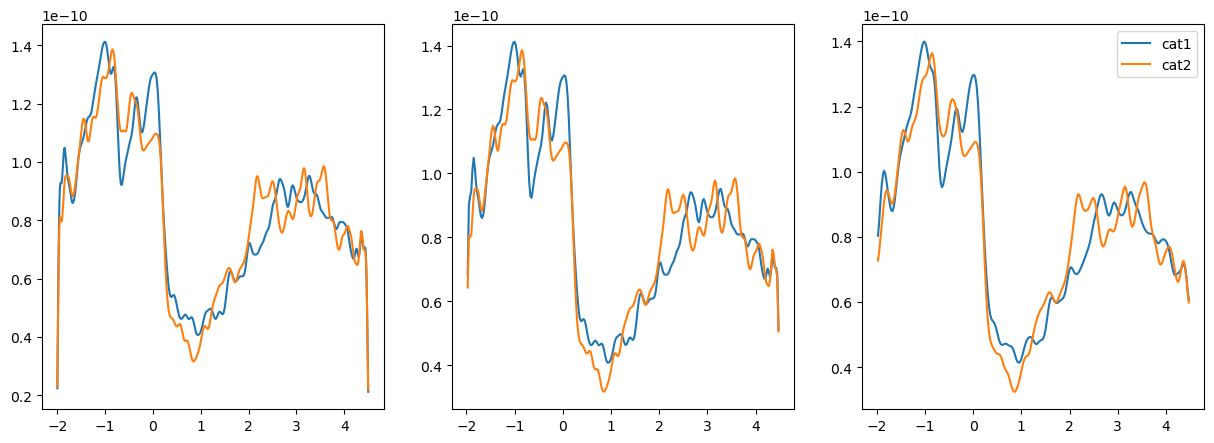

In [5]:
from scipy.signal import hilbert
w_size = 1.5
down_wsize = 25
freq_band = 'alpha'
pow_or_phase = 'pow'
if freq_band == 'alpha':
    lf, hf = 8, 14
elif freq_band == 'beta':
    lf, hf = 14, 20
elif freq_band == 'theta':
    lf, hf = 4, 8

t_array = epochData.times
# X = epochData.get_data(copy=True)
tempData = epochData.get_data(copy=True)

# tempData = (tempData - tempData.mean(axis=0)) / tempData.std(axis=0)
X = mne.filter.filter_data(tempData, sfreq=epochData.info['sfreq'], l_freq=lf, h_freq=hf, verbose=True, n_jobs=-1)
if pow_or_phase == 'pow':
    X = np.abs(hilbert(X)) ** 2
elif pow_or_phase == 'phase':
    X = np.angle(hilbert(X))

# occ_elecs =  left_occ_elecs + right_occ_elecs 
# occ_elecs = left_par_elecs + right_par_elecs 
occ_elecs = left_elecs + right_elecs
occElecsIdx = [epochDataBasecorr.ch_names.index(elec) for elec in occ_elecs]
X = X[:, occElecsIdx, :]
# X = np.log10(X)

y_hemi = behav_df['stimPF'].values
y_ori = behav_df['targOriCategory'].values
y_ori_cat = [0 if ori == 30 or ori == 120 else 1 for ori in y_ori]

y__ = np.empty_like(y_ori)
y__[((np.array(y_ori) == 30) | (np.array(y_ori) == 60)) & (np.array(y_hemi) == 1)] = 0
y__[((np.array(y_ori) == 30) | (np.array(y_ori) == 60)) & (np.array(y_hemi) == 0)] = 1
y__[((np.array(y_ori) == 120) | (np.array(y_ori) == 150)) & (np.array(y_hemi) == 1)] = 2
y__[((np.array(y_ori) == 120) | (np.array(y_ori) == 150)) & (np.array(y_hemi) == 0)] = 3

# y__ = [0 if y__ == 0 or y__ == 2 else 1 for y__ in y__]
# print(np.unique(y__))

# c1_trls = np.where(((np.array(y_ori) == 30) | (np.array(y_ori) == 60)) & (np.array(y_hemi) == 1))[0]
# c2_trls = np.where(((np.array(y_ori) == 30) | (np.array(y_ori) == 60)) & (np.array(y_hemi) == 0))[0]
# c3_trls = np.where(((np.array(y_ori) == 120) | (np.array(y_ori) == 150)) & (np.array(y_hemi) == 1))[0]
# c4_trls = np.where(((np.array(y_ori) == 120) | (np.array(y_ori) == 150)) & (np.array(y_hemi) == 0))[0]
# c2_trls = np.where(np.array(y_ori) == 60)[0]
# c3_trls = np.where(np.array(y_ori) == 120)[0]
# c4_trls = np.where(np.array(y_ori) == 150)[0]

c1_trls = y_hemi == 1
c2_trls = y_hemi == 0

# X_down, t_array_down = moving_average_downsample(X, t_array, window_size=down_wsize)
X_down, t_array_down = X[:, :, down_wsize:-down_wsize:down_wsize], t_array[down_wsize:-down_wsize:down_wsize]
# X_smooth = smooth_data(X, window_size=w_size)
X_smooth = gaussian_smooth_1d(X_down, sigma=w_size)

if pow_or_phase == 'pow':
    f, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].plot(t_array, X[c1_trls, :, :].mean(axis=(0,1)), label='cat1')
    ax[0].plot(t_array, X[c2_trls, :, :].mean(axis=(0,1)), label='cat2')
    ax[1].plot(t_array_down, X_down[c1_trls, :, :].mean(axis=(0,1)), label='cat1')
    ax[1].plot(t_array_down, X_down[c2_trls, :, :].mean(axis=(0,1)), label='cat2')
    ax[2].plot(t_array_down, X_smooth[c1_trls, :, :].mean(axis=(0,1)), label='cat1')
    ax[2].plot(t_array_down, X_smooth[c2_trls, :, :].mean(axis=(0,1)), label='cat2')
    plt.legend()
    plt.show()
else:
    from scipy.stats import circmean
    f, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].plot(t_array, circmean(X[c1_trls, :, :], axis=(0,1), high=np.pi, low=-np.pi), label='cat1')
    ax[0].plot(t_array, circmean(X[c2_trls, :, :], axis=(0,1), high=np.pi, low=-np.pi), label='cat2')
    ax[1].plot(t_array_down, circmean(X_down[c1_trls, :, :], axis=(0,1), high=np.pi, low=-np.pi), label='cat1')
    ax[1].plot(t_array_down, circmean(X_down[c2_trls, :, :], axis=(0,1), high=np.pi, low=-np.pi), label='cat2')
    ax[2].plot(t_array_down, circmean(X_smooth[c1_trls, :, :], axis=(0,1), high=np.pi, low=-np.pi), label='cat1')
    ax[2].plot(t_array_down, circmean(X_smooth[c2_trls, :, :], axis=(0,1), high=np.pi, low=-np.pi), label='cat2')
    plt.legend()
    plt.show()



# f, ax = plt.subplots(1, 3, figsize=(15, 5))
# ax[0].plot(t_array, X[c1_trls, :, :].mean(axis=(0,1)), label='cat1')
# ax[0].plot(t_array, X[c2_trls, :, :].mean(axis=(0,1)), label='cat2')
# ax[0].plot(t_array, X[c3_trls, :, :].mean(axis=(0,1)), label='cat3')
# ax[0].plot(t_array, X[c4_trls, :, :].mean(axis=(0,1)), label='cat4')
# ax[1].plot(t_array_down, X_down[c1_trls, :, :].mean(axis=(0,1)), label='cat1')
# ax[1].plot(t_array_down, X_down[c2_trls, :, :].mean(axis=(0,1)), label='cat2')
# ax[1].plot(t_array_down, X_down[c3_trls, :, :].mean(axis=(0,1)), label='cat3')
# ax[1].plot(t_array_down, X_down[c4_trls, :, :].mean(axis=(0,1)), label='cat4')
# ax[2].plot(t_array_down, X_smooth[c1_trls, :, :].mean(axis=(0,1)), label='cat1')
# ax[2].plot(t_array_down, X_smooth[c2_trls, :, :].mean(axis=(0,1)), label='cat2')
# ax[2].plot(t_array_down, X_smooth[c3_trls, :, :].mean(axis=(0,1)), label='cat3')
# ax[2].plot(t_array_down, X_smooth[c4_trls, :, :].mean(axis=(0,1)), label='cat4')
# plt.legend()
# plt.show()

In [6]:
from sklearn.svm import SVC

clf_temporal = make_pipeline(
    Vectorizer(),
    # StandardScaler(),
    # LogisticRegression(solver='liblinear'),
    # LinearModel(LogisticRegression(solver='liblinear')),
    SVC(kernel='rbf', C=1),
    # SVC(kernel='rbf', C=1, decision_function_shape='ovr', probability=True),
)

gen_decod = GeneralizingEstimator(clf_temporal, n_jobs=-1, scoring='roc_auc', verbose=True)
# gen_decod = GeneralizingEstimator(clf_temporal, n_jobs=4, scoring='roc_auc_ovr', verbose=True)

# scores = cross_val_multiscore(gen_decod, X_smooth, y_ori_cat, cv=5, n_jobs=-1)
# create dummies for y_ori
y_ori_dum = pd.Categorical(y__).codes

scores = cross_val_multiscore(gen_decod, X_smooth, y_hemi, cv=5, n_jobs=-1)

scores_mean = np.mean(scores, axis=0)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.







  0%|          | Fitting GeneralizingEstimator : 0/259 [00:00<?,       ?it/s]


  0%|          | Fitting GeneralizingEstimator : 0/259 [00:00<?,       ?it/s]
  4%|▍         | Fitting GeneralizingEstimator : 10/259 [00:00<00:01,  208.69it/s]



  3%|▎         | Fitting GeneralizingEstimator : 7/259 [00:00<00:02,  107.47it/s]

  7%|▋         | Fitting GeneralizingEstimator : 17/259 [00:00<00:01,  234.16it/s]


 16%|█▌        | Fitting GeneralizingEstimator : 41/259 [00:00<00:00,  349.35it/s]
  5%|▌         | Fitting GeneralizingEstimator : 14/259 [00:00<00:02,  105.28it/s]



 17%|█▋        | Fitting GeneralizingEstimator : 45/259 [00:00<00:00,  333.54it/s]

 19%|█▉        | Fitting GeneralizingEstimator : 49/259 [00:00<00:00,  306.24it/s]
 22%|██▏       | Fitting GeneralizingEstimator : 56/259 [00:00<00:00,  324.27it/s]



 22%|██▏       | Fitting GeneralizingEstimator : 58/259 [00:00<00:00,  320.96it/s]


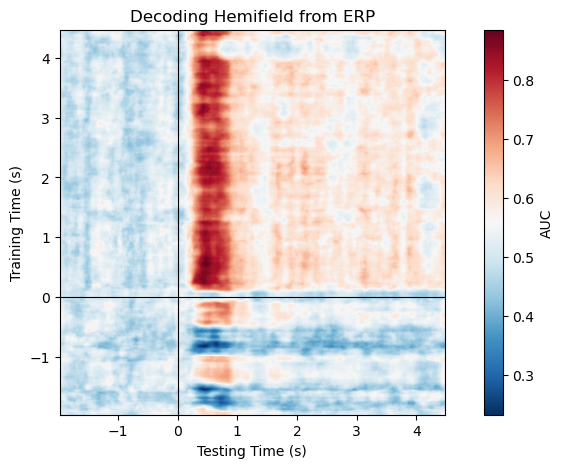

In [8]:
f, ax = plt.subplots(1, 1, figsize=(10, 5))
im = ax.imshow(scores_mean, 
               interpolation='lanczos', 
               origin='lower', 
               cmap='RdBu_r', 
               extent=[t_array_down[0], t_array_down[-1], t_array_down[0], t_array_down[-1]],
               )
ax.axhline(0, color='k', lw=0.8)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('Testing Time (s)')
ax.set_ylabel('Training Time (s)')
# ax.set_title('Decoding Hemifield from ERP')
ax.set_title('Decoding Hemifield from ERP')
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('AUC')
plt.show()

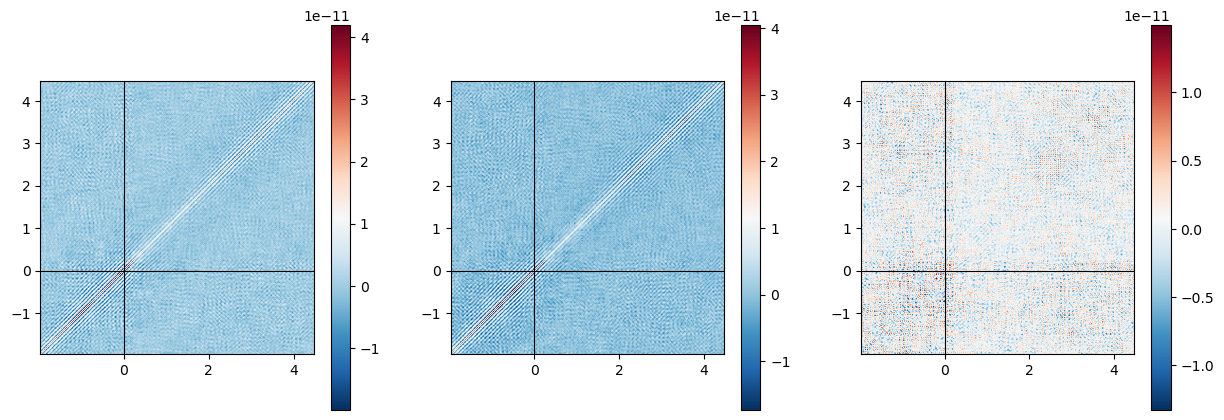

In [195]:
f, axs = plt.subplots(1, 3, figsize=(15, 5))
data_1 = X_down[inPF_trials, :, :].mean(axis=(1))
data_2 = X_down[outPF_trials, :, :].mean(axis=(1))
data_3 = data_1 - data_2

# data_1 = StandardScaler().fit_transform(data_1)
# data_2 = StandardScaler().fit_transform(data_2)
# data_3 = StandardScaler().fit_transform(data_3)

RSA_1 = (data_1.T @ data_1) / data_1.shape[1]
RSA_2 = (data_2.T @ data_2) / data_2.shape[1]
# RSA_3 = (data_3.T @ data_3) / data_3.shape[1]
RSA_3 = RSA_1 - RSA_2

im1 = axs[0].imshow(RSA_1, interpolation='lanczos', origin='lower', cmap='RdBu_r', extent=[t_array_down[0], t_array_down[-1], t_array_down[0], t_array_down[-1]],
                    )
axs[0].axhline(0, color='k', lw=0.8)
axs[0].axvline(0, color='k', lw=0.8)
f.colorbar(im1, ax=axs[0])
im2 = axs[1].imshow(RSA_2, interpolation='lanczos', origin='lower', cmap='RdBu_r', extent=[t_array_down[0], t_array_down[-1], t_array_down[0], t_array_down[-1]],
                    )
axs[1].axhline(0, color='k', lw=0.8)
axs[1].axvline(0, color='k', lw=0.8)
f.colorbar(im2, ax=axs[1])
im3 = axs[2].imshow(RSA_3, interpolation='lanczos', origin='lower', cmap='RdBu_r', extent=[t_array_down[0], t_array_down[-1], t_array_down[0], t_array_down[-1]],
                    )
axs[2].axhline(0, color='k', lw=0.8)
axs[2].axvline(0, color='k', lw=0.8)
f.colorbar(im3, ax=axs[2])


plt.show()





# # plt.figure(figsize=(10, 5))
# # plt.plot(t_array_down, scores_mean.diagonal(), label='Decoding accuracy')
# low_tidx = np.where(t_array > 0.2)[0][0]
# high_tidx = np.where(t_array > 1)[0][0]
# data_1 = X[inPF_trials, :, :].mean(axis=(1))
# data_2 = X[outPF_trials, :, :].mean(axis=(1))
# data_ = np.concatenate([data_1, data_2], axis=0)
# sc = StandardScaler()
# data_ = sc.fit_transform(data_)
# plt.imshow(data_.T @ data_, # - np.eye(scores_mean.shape[0]), 
#            interpolation='lanczos', 
#            origin='lower', 
#            cmap='RdBu_r', 
#            extent=[t_array_down[0], t_array_down[-1], t_array_down[0], t_array_down[-1]],
#            vmin = 0, vmax = 200,
#           )
# plt.axhline(0, color='k', lw=0.8)
# plt.axvline(0, color='k', lw=0.8)
# # plt.title('Decoding Hemifield from ERP')
# plt.title('RSA of Alpha power')
# plt.colorbar()
# plt.show()

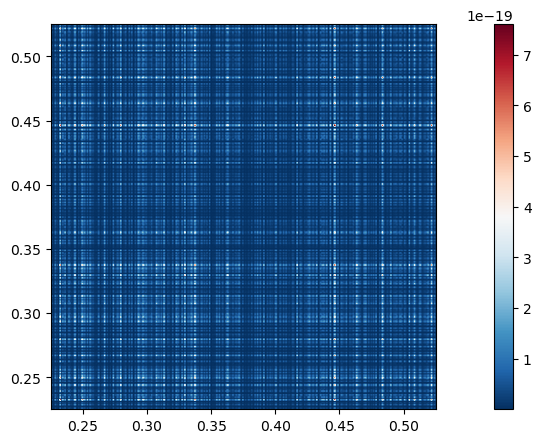

In [9]:
f, axs = plt.subplots(1, 1, figsize=(15, 5))
low_tidx = np.where(t_array_down > 0.2)[0][0]
high_tidx = np.where(t_array_down > 0.5)[0][0]
data_1 = X_down[inPF_trials, :, low_tidx:high_tidx].mean(axis=(1))
data_2 = X_down[outPF_trials, :, low_tidx:high_tidx].mean(axis=(1))
data = np.concatenate([data_1, data_2], axis=0)
RSA_ = data @ data.T
im = axs.imshow(RSA_, # - np.eye(scores_mean.shape[0]), 
           interpolation='lanczos', 
           origin='lower', 
           cmap='RdBu_r', 
           extent=[t_array_down[low_tidx], t_array_down[high_tidx], t_array_down[low_tidx], t_array_down[high_tidx]],
          )
f.colorbar(im, ax=axs)
plt.show()


In [16]:
scores_mean = SvM_with_ECOC(X_down, pd.Categorical(y__).codes)

  0%|          | Fitting GeneralizingEstimator : 0/259 [00:00<?,       ?it/s]

  0%|          | Scoring GeneralizingEstimator : 0/67081 [00:00<?,       ?it/s]

ValueError: scoring must return a number, got [[0.28571429 0.31746032 0.31746032 ... 0.20634921 0.26984127 0.23809524]
 [0.28571429 0.3015873  0.25396825 ... 0.22222222 0.17460317 0.22222222]
 [0.20634921 0.26984127 0.36507937 ... 0.26984127 0.22222222 0.3015873 ]
 ...
 [0.28571429 0.3015873  0.36507937 ... 0.23809524 0.3015873  0.26984127]
 [0.34920635 0.28571429 0.25396825 ... 0.20634921 0.25396825 0.28571429]
 [0.33333333 0.20634921 0.19047619 ... 0.28571429 0.28571429 0.26984127]] (<class 'numpy.ndarray'>) instead. (scorer=score)

In [ ]:
f, ax = plt.subplots(1, 1, figsize=(10, 5))
im = ax.imshow(scores_mean, 
               interpolation='lanczos', 
               origin='lower', 
               cmap='RdBu_r', 
               extent=[t_array_down[0], t_array_down[-1], t_array_down[0], t_array_down[-1]],
               )
ax.axhline(0, color='k', lw=0.8)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('Testing Time (s)')
ax.set_ylabel('Training Time (s)')
# ax.set_title('Decoding Hemifield from ERP')
ax.set_title('Decoding Hemifield from ERP')
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('AUC')
plt.show()

In [ ]:
evokedinPF = epochData[inPF_trials].average()
evokedoutPF = epochData[outPF_trials].average()
f, axs = plt.subplots(2, 2, figsize=(15, 10))
axs= axs.flatten()
evokedinPF.plot(picks=left_occ_elecs, show=False, axes=axs[0])
evokedoutPF.plot(picks=left_occ_elecs, show=False, axes=axs[1])
evokedinPF.plot(picks=right_occ_elecs, show=False, axes=axs[2])
evokedoutPF.plot(picks=right_occ_elecs, show=False, axes=axs[3])
for ax in axs:
    ax.set_ylim(-6, 6)
    ax.set_ylabel('Voltage (uV)')
    ax.set_xlabel('Time (s)')
    ax.text(-1, 5.5, 'F', fontsize=12, color='black')
    ax.text(0, 5.5, 'S', fontsize=12, color='black')
    ax.text(0.25, 5.5, 'D', fontsize=12, color='black')

# axs[0].text(0, -4, 'F', fontsize=12, color='black')
axs[0].set_title('inPF - Left Occipital')
axs[1].set_title('outPF - Left Occipital')
axs[2].set_title('inPF - Right Occipital')
axs[3].set_title('outPF - Right Occipital')
plt.show()

In [ ]:
# Compute PSD for each condition
tstart = raw_data.time_as_index(0)[0]
tend = raw_data.time_as_index(2.5)[0]
psd_inPF = epochData[inPF_trials].compute_psd(fmin=1, fmax=50, method='welch', n_fft=2048, n_overlap=1024, tmin=tstart, tmax=tend)
psd_outPF = epochData[outPF_trials].compute_psd(fmin=1, fmax=50, method='welch', n_fft=2048, n_overlap=1024, tmin=tstart, tmax=tend)

f, axs = plt.subplots(2, 2, figsize=(15, 10))
axs = axs.flatten()

psd_inPF.plot(picks=left_occ_elecs, show=False, axes=axs[0])
axs[0].set_title('inPF - Left Occipital')

psd_outPF.plot(picks=left_occ_elecs, show=False, axes=axs[1])
axs[1].set_title('outPF - Left Occipital')

psd_inPF.plot(picks=right_occ_elecs, show=False, axes=axs[2])
axs[2].set_title('inPF - Right Occipital')

psd_outPF.plot(picks=right_occ_elecs, show=False, axes=axs[3])
axs[3].set_title('outPF - Right Occipital')

# Customize the plots
for ax in axs:
    ax.set_ylabel('Power (uV^2/Hz)')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylim(-16, 16)  

plt.show()

In [ ]:
freqs = np.arange(8, 13, 0.5)
n_cycles = freqs / 2
alpha_power_inPF_left = mne.time_frequency.tfr_morlet(epochDataBasecorr[inPF_trials], 
                                                freqs=freqs,
                                                n_cycles=n_cycles, use_fft=True,
                                                return_itc=False,
                                                average=False,
                                                picks=left_occ_elecs,
                                                decim=3,
                                                n_jobs=7)
alpha_power_inPF_right = mne.time_frequency.tfr_morlet(epochDataBasecorr[inPF_trials],
                                                    freqs=freqs,
                                                    n_cycles=n_cycles, use_fft=True,
                                                    return_itc=False,
                                                    average=False,
                                                    picks=right_occ_elecs,
                                                    decim=3,
                                                    n_jobs=7)
alpha_power_outPF_left = mne.time_frequency.tfr_morlet(epochDataBasecorr[outPF_trials],
                                                freqs=freqs,
                                                n_cycles=n_cycles, use_fft=True,
                                                return_itc=False,
                                                average=False,
                                                picks=left_occ_elecs,
                                                decim=3,
                                                n_jobs=7)
alpha_power_outPF_right = mne.time_frequency.tfr_morlet(epochDataBasecorr[outPF_trials],
                                                freqs=freqs,
                                                n_cycles=n_cycles, use_fft=True,
                                                return_itc=False,
                                                average=False,
                                                picks=right_occ_elecs,
                                                decim=3,
                                                n_jobs=7)

In [ ]:
tstart = alpha_power_inPF_left.time_as_index(-1.5)[0]
tend = alpha_power_inPF_left.time_as_index(4.5)[0]
base_tstart = alpha_power_inPF_left.time_as_index(-1)[0]
base_tend = alpha_power_inPF_left.time_as_index(0)[0]

data_inPF_left = alpha_power_inPF_left.data.mean(axis=(1, 2))
data_inPF_left_baseline = data_inPF_left[:, base_tstart:base_tend].mean(axis=1)
data_inPF_left = 10 * np.log10(data_inPF_left[:, tstart:tend] / data_inPF_left_baseline[:, np.newaxis])

data_inPF_right = alpha_power_inPF_right.data.mean(axis=(1, 2))
data_inPF_right_baseline = data_inPF_right[:, base_tstart:base_tend].mean(axis=1)
data_inPF_right = 10 * np.log10(data_inPF_right[:, tstart:tend] / data_inPF_right_baseline[:, np.newaxis])

data_outPF_left = alpha_power_outPF_left.data.mean(axis=(1, 2))
data_outPF_left_baseline = data_outPF_left[:, base_tstart:base_tend].mean(axis=1)
data_outPF_left = 10 * np.log10(data_outPF_left[:, tstart:tend] / data_outPF_left_baseline[:, np.newaxis])

data_outPF_right = alpha_power_outPF_right.data.mean(axis=(1, 2))
data_outPF_right_baseline = data_outPF_right[:, base_tstart:base_tend].mean(axis=1)
data_outPF_right = 10 * np.log10(data_outPF_right[:, tstart:tend] / data_outPF_right_baseline[:, np.newaxis])

In [ ]:
f, axs = plt.subplots(2, 2, figsize=(15, 10))
axs = axs.flatten()
axs[0].plot(alpha_power_inPF_left.times[tstart:tend], data_inPF_left.mean(axis=0), label='inPF Left Occipital')
axs[0].plot(alpha_power_inPF_left.times[tstart:tend], data_inPF_right.mean(axis=0), label='inPF Right Occipital')
axs[0].set_xlabel('Time (s)')
axs[0].set_ylabel('Relative Power (dB)')
axs[0].set_ylim(-7, 1)
axs[0].axhline(0, color='black', linestyle='--')
axs[0].legend()

axs[1].plot(alpha_power_inPF_left.times[tstart:tend], data_outPF_left.mean(axis=0), label='outPF Left Occipital')
axs[1].plot(alpha_power_inPF_left.times[tstart:tend], data_outPF_right.mean(axis=0), label='outPF Right Occipital')
axs[1].set_xlabel('Time (s)')
axs[1].set_ylabel('Relative Power (dB)')
axs[1].set_ylim(-7, 1)
axs[1].axhline(0, color='black', linestyle='--')
axs[1].legend()

axs[2].plot(alpha_power_inPF_left.times[tstart:tend], data_inPF_left.mean(axis=0) - data_inPF_right.mean(axis=0), label='inPF Left - Right Occipital')
axs[2].plot(alpha_power_inPF_left.times[tstart:tend], data_outPF_left.mean(axis=0) - data_outPF_right.mean(axis=0), label='outPF Left - Right Occipital')
axs[2].set_xlabel('Time (s)')
axs[2].set_label('Relative Power (dB)')
axs[2].set_ylim(-2, 2)
axs[2].axhline(0, color='black', linestyle='--')
axs[2].legend()

axs[3].plot(alpha_power_inPF_left.times[tstart:tend], data_inPF_left.mean(axis=0) - data_outPF_left.mean(axis=0), label='inPF - outPF Left Occipital')
axs[3].plot(alpha_power_inPF_left.times[tstart:tend], data_inPF_right.mean(axis=0) - data_outPF_right.mean(axis=0), label='inPF - outPF Right Occipital')
axs[3].set_xlabel('Time (s)')
axs[3].set_ylabel('Relative Power (dB)')
axs[3].set_ylim(-2, 2)
axs[3].axhline(0, color='black', linestyle='--')
axs[3].legend()

plt.show()
    

In [ ]:
tstart = alpha_power_inPF_left.time_as_index(0)[0]
tend = alpha_power_inPF_left.time_as_index(4.5)[0]
base_tstart = alpha_power_inPF_left.time_as_index(-1)[0]
base_tend = alpha_power_inPF_left.time_as_index(0)[0]

data_inPF_left = alpha_power_inPF_left.data.mean(axis=(1, 2))
data_inPF_left_baseline = data_inPF_left[:, base_tstart:base_tend].mean(axis=1)
data_inPF_left = 10 * np.log10(data_inPF_left[:, tstart:tend] / data_inPF_left_baseline[:, np.newaxis])

data_inPF_right = alpha_power_inPF_right.data.mean(axis=(1, 2))
data_inPF_right_baseline = data_inPF_right[:, base_tstart:base_tend].mean(axis=1)
data_inPF_right = 10 * np.log10(data_inPF_right[:, tstart:tend] / data_inPF_right_baseline[:, np.newaxis])

data_outPF_left = alpha_power_outPF_left.data.mean(axis=(1, 2))
data_outPF_left_baseline = data_outPF_left[:, base_tstart:base_tend].mean(axis=1)
data_outPF_left = 10 * np.log10(data_outPF_left[:, tstart:tend] / data_outPF_left_baseline[:, np.newaxis])

data_outPF_right = alpha_power_outPF_right.data.mean(axis=(1, 2))
data_outPF_right_baseline = data_outPF_right[:, base_tstart:base_tend].mean(axis=1)
data_outPF_right = 10 * np.log10(data_outPF_right[:, tstart:tend] / data_outPF_right_baseline[:, np.newaxis])

data_inPF = np.concatenate([data_inPF_left, data_outPF_left], axis=0)
plotRSA(data_inPF, alpha_power_inPF_left.times[tstart:tend], 1, 0.2)

In [ ]:
RunRSA(epochDataBasecorr, behav_df, 'alpha', 'byPF', 'left_occ', trange=[0,4.5], baseCorr=True)

In [ ]:
plotDiffRSA(data_inPF_left, data_inPF_right, 1, 0.1)

In [ ]:
plt.figure(figsize=(10, 10))
plt.imshow(alpha_power_inPF, cmap='viridis')
plt.colorbar()
plt.show()

In [ ]:
freqs = np.linspace(8, 12, 30)
n_cycles = freqs / 2
powerInPF = mne.time_frequency.tfr_morlet(epochDataBasecorr[inPF_trials], 
                                                    freqs=freqs, 
                                                    n_cycles=n_cycles, 
                                                    return_itc=False, 
                                                    decim=3, 
                                                    n_jobs=7)

In [ ]:
behav_df_temp = behav_df.copy()
behav_df_temp.iloc[inPF_trials]['targX'].value_counts()

In [ ]:
powData = powerInPF.data
tlow = powerInPF.time_as_index(-1)[0]
thigh = powerInPF.time_as_index(0)[0]
leftIdx = [rawDataNew.ch_names.index(ch) for ch in left_occ_elecs]
rightIdx = [rawDataNew.ch_names.index(ch) for ch in right_occ_elecs]
powLeft = powData[leftIdx, :, :].mean(axis=0)
powRight = powData[rightIdx, :, :].mean(axis=0)
powDiff = powLeft / powRight
baseLeft = powLeft[:, tlow:thigh].mean(axis=1)
baseRight = powRight[:, tlow:thigh].mean(axis=1)
baseDiff = powDiff[:, tlow:thigh].mean(axis=1)
powLeft = 10 * np.log10(powLeft / baseLeft[:, None])
powRight = 10 * np.log10(powRight / baseRight[:, None])
powDiff = 10 * np.log10(powDiff / baseDiff[:, None])
f, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(powLeft, aspect='auto', origin='lower', extent=[-2, 2.5, 5, 55])
axs[1].imshow(powRight, aspect='auto', origin='lower', extent=[-2, 2.5, 5, 55])
axs[2].imshow(powDiff, aspect='auto', origin='lower', extent=[-2, 2.5, 5, 55])
plt.show()

In [ ]:
powerInPF.plot(picks=right_occ_elecs, baseline=(None, -1), mode='logratio', show=True)
plt.show()

In [ ]:
freqs = np.logspace(*np.log10([6, 35]), num=8)
n_cycles = freqs / 2.0  # different number of cycle per frequency
power, itc = epochs.compute_tfr(
    method="morlet",
    freqs=freqs,
    n_cycles=n_cycles,
    average=True,
    return_itc=True,
    decim=3,
)

In [ ]:
leftIdx = [rawDataNew.ch_names.index(ch) for ch in left_occ_elecs]
rightIdx = [rawDataNew.ch_names.index(ch) for ch in right_occ_elecs]
leftPowInPF = powerInPF.get_data(copy=True)[:,leftIdx,:].mean(axis=(0, 1))
rightPowInPF = powerInPF.get_data(copy=True)[:,rightIdx,:].mean(axis=(0, 1))
diffPowInPF = (leftPowInPF - rightPowInPF) / (leftPowInPF + rightPowInPF)
leftPowOutPF = powerOutPF.get_data(copy=True)[:,leftIdx,:].mean(axis=(0, 1))
rightPowOutPF = powerOutPF.get_data(copy=True)[:,rightIdx,:].mean(axis=(0, 1))
diffPowOutPF = (leftPowOutPF - rightPowOutPF) / (leftPowOutPF + rightPowOutPF)

f, axs = plt.subplots(2, 2, figsize=(15, 10))
axs = axs.flatten()
axs[0].plot(powerInPF.times, leftPowInPF, label='Left')
axs[0].plot(powerInPF.times, rightPowInPF, label='Right')
axs[0].set_title('inPF - ' + band_to_plot)
axs[0].set_ylabel('Power (uV^2)')
axs[0].set_xlabel('Time (s)')
axs[0].legend()

axs[1].plot(powerOutPF.times, leftPowOutPF, label='Left')
axs[1].plot(powerOutPF.times, rightPowOutPF, label='Right')
axs[1].set_title('outPF - ' + band_to_plot)
axs[1].set_ylabel('Power (uV^2)')
axs[1].set_xlabel('Time (s)')
axs[1].legend()

axs[2].plot(powerInPF.times, diffPowInPF)
axs[2].set_title('inPF - Left - Right')
axs[2].set_ylabel('Power (uV^2)')
axs[2].set_xlabel('Time (s)')
axs[2].axhline(0, color='black', linestyle='--')

axs[3].plot(powerOutPF.times, diffPowOutPF)
axs[3].set_title('outPF - Left - Right')
axs[3].set_ylabel('Power (uV^2)')
axs[3].set_xlabel('Time (s)')
axs[3].axhline(0, color='black', linestyle='--')

plt.tight_layout()
plt.show()

In [ ]:
tlowIdx = epochData.time_as_index(-1)[0]
thighIdx = epochData.time_as_index(4)[0]
leftIdx = [rawDataNew.ch_names.index(ch) for ch in left_occ_elecs]
rightIdx = [rawDataNew.ch_names.index(ch) for ch in right_occ_elecs]
dataInPF = np.mean(epochData[inPF_trials].get_data(copy=True)[:, leftIdx, tlowIdx:thighIdx], axis=1) \
        - np.mean(epochData[inPF_trials].get_data(copy=True)[:, rightIdx, tlowIdx:thighIdx], axis=1)
dataOutPF = np.mean(epochData[outPF_trials].get_data(copy=True)[:, leftIdx, tlowIdx:thighIdx], axis=1) \
        - np.mean(epochData[outPF_trials].get_data(copy=True)[:, rightIdx, tlowIdx:thighIdx], axis=1)
plotDiffRSA(dataInPF, dataOutPF, dim=1)

In [ ]:
plt.figure()
plt.hist(RSA_diff.flatten(), bins=100)
plt.show()

In [ ]:
plt.figure()
plt.hist(RSA_data[RSA_data != 0].flatten(), bins=100)
plt.show()

In [ ]:
plt.figure(figsize=(8, 8))

data1 = powerInPF.get_data(copy=True).mean(axis=1)
data2 = powerOutPF.get_data(copy=True).mean(axis=1)
this_data = np.concatenate((powerInPF.get_data(copy=True).mean(axis=1), powerOutPF.get_data(copy=True).mean(axis=1)), axis=0)
prod_data = this_data @ this_data.T
qt_thresh = 0.25
l_qt = np.quantile(prod_data, qt_thresh)
u_qt = np.quantile(prod_data, 1 - qt_thresh)
plt.imshow(prod_data, aspect='auto', origin='lower', cmap='viridis', vmin=l_qt, vmax=u_qt)
plt.colorbar()
plt.show()
#powerInPF.get_data().shape

In [ ]:
powerInPF.plot(picks='all', show=True)
plt.show()#, baseline=None, mode='logratio', title='inPF - ' + band_to_plot)

In [ ]:
powerInPF

In [ ]:
times_to_plot = np.linspace(-1, 2.5, 6)
qtl_thresh = 0.01

# Figure for inPF condition
fig, axs = plt.subplots(1, len(times_to_plot)-1, figsize=(15, 4))
axs = axs.flatten()
for i, time in enumerate(times_to_plot[:-1]):
    idx_start = powerInPF.time_as_index(time)
    idx_end = powerInPF.time_as_index(times_to_plot[i+1]) 
    idx_start = idx_start[0]
    idx_end = idx_end[0] 
    
    avg_powerInPF = np.mean(np.abs(powerInPF.get_data(copy=True)[:, :, idx_start:idx_end])**2, axis=(0,-1)) 
    avg_powerOutPF = np.mean(np.abs(powerOutPF.get_data(copy=True)[:, :, idx_start:idx_end])**2, axis=(0,-1))

    low_qtl = np.quantile(avg_powerInPF, qtl_thresh)
    high_qtl = np.quantile(avg_powerInPF, 1-qtl_thresh)
    
    mne.viz.plot_topomap(avg_powerInPF, powerInPF.info, axes=axs[i], show=False, cmap='RdBu_r', vlim=(low_qtl, high_qtl))
    axs[i].set_title(f'Time: {time:.2f}s')

plt.suptitle(f'{band_to_plot} power topomap (outPF)', fontsize=12)
plt.show()

# Figure for outPF condition
fig, axs = plt.subplots(1, len(times_to_plot)-1, figsize=(15, 4))
axs = axs.flatten()
for i, time in enumerate(times_to_plot[:-1]):
    idx_start = powerOutPF.time_as_index(time)
    idx_end = powerOutPF.time_as_index(times_to_plot[i+1]) 
    idx_start = idx_start[0]
    idx_end = idx_end[0] 
    
    avg_powerInPF = np.mean(np.abs(powerInPF.get_data(copy=True)[:, :, idx_start:idx_end])**2, axis=(0,-1)) 
    avg_powerOutPF = np.mean(np.abs(powerOutPF.get_data(copy=True)[:, :, idx_start:idx_end])**2, axis=(0,-1))

    low_qtl = np.quantile(avg_powerInPF, qtl_thresh)
    high_qtl = np.quantile(avg_powerInPF, 1-qtl_thresh)
    
    mne.viz.plot_topomap(avg_powerOutPF, powerOutPF.info, axes=axs[i], show=False, cmap='RdBu_r', vlim=(low_qtl, high_qtl))
    axs[i].set_title(f'Time: {time:.2f}s')

plt.suptitle(f'{band_to_plot} power topomap (outPF)', fontsize=12)
plt.show()

In [ ]:
window_size = 0.5
overlap = 0.1
freq_band = 'alpha'
bandPower, twindow_power = getPower(trials_list, window_size, overlap, freq_band)
   

In [ ]:
plt.figure()
plt.hist(bandPower.flatten(), bins=100)
plt.show()

In [ ]:
# leftTrials = trials_list[trials_list['instimPF'] == 1]
inPF_trials = behav_df[behav_df['stimPF'] == 0].index 
outPF_trials = behav_df[behav_df['stimPF'] == 1].index
# leftbandPower = bandPower[leftTrials, :, :]
ch_names = trials_list[0].ch_names
sfreq = trials_list[0].info['sfreq']
# Plot a topo plot of the power
info = mne.create_info(ch_names, sfreq, ch_types='eeg')
montage = trials_list[0].get_montage()
info.set_montage(montage)

data_window = np.mean(bandPower[inPF_trials, :, :], axis=(0,))
# bandPower_corrected = data_window.copy()

baseline_time = np.where((twindow_power[0] >= 1) & (twindow_power[0] < 2))[0]
baseline_ = data_window[:, baseline_time]
baseline_average = np.mean(baseline_, axis=(1))
baseline_average = np.expand_dims(baseline_average, axis=(1))
# baseline_average = np.expand_dims(baseline_average, axis=2)
bandPower_corrected = (data_window - baseline_average) / baseline_average
bandPower_corrected = data_window / baseline_average
qt_thresh = 0.01
qt_low = np.quantile(bandPower_corrected, qt_thresh)
qt_high = np.quantile(bandPower_corrected, 1-qt_thresh)
evoked = mne.EvokedArray(bandPower_corrected, info)
# evoked = mne.EvokedArray(data_window[:, np.newaxis], info)
times = np.linspace(1, 6, 10)
evoked.plot_topomap(times=times, show=True, time_unit='s', scalings=1, time_format='%.2f', cmap='RdBu_r',
                    image_interp='nearest', ch_type='eeg', colorbar=True, res=120, vlim=(qt_low, qt_high))
plt.show()


In [ ]:
plt.figure()
plt.hist(bandPower_corrected.flatten(), bins=100)
plt.show()

In [ ]:
leftOccElecsIdx = [trials_list[0].ch_names.index(ch) for ch in left_occ_elecs]
rightOccElecsIdx = [trials_list[0].ch_names.index(ch) for ch in right_occ_elecs]
leftOccBandPower = bandPower[:, leftOccElecsIdx, :]
rightOccBandPower = bandPower[:, rightOccElecsIdx, :]

# leftPower = left_occ_alpha_power.copy()
# rightPower = right_occ_alpha_power.copy()

# left_occ_alpha_power = (leftPower-rightPower) / (leftPower+rightPower+1e-10)
# right_occ_alpha_power = (rightPower-leftPower) / (rightPower+leftPower+1e-10)

# # left_occ_alpha_power = (left_occ_alpha_power - right_occ_alpha_power) / (left_occ_alpha_power + right_occ_alpha_power + 1e-10)
# # right_occ_alpha_power = (right_occ_alpha_power - left_occ_alpha_power) / (right_occ_alpha_power + left_occ_alpha_power + 1e-10)
baseline_time = np.where((twindow_power[0] > 1) & (twindow_power[0] < 2))
baseline_average = (np.mean(leftOccBandPower[:, :, baseline_time]) + np.mean(rightOccBandPower[:, :, baseline_time])) / 2

# left_occ_alpha_power /= baseline_average
# right_occ_alpha_power /= baseline_average

leftOccBandPower = (leftOccBandPower - baseline_average) / baseline_average
rightOccBandPower = (rightOccBandPower - baseline_average) / baseline_average

conds_power = 'byOri'
plotPower(leftOccBandPower, rightOccBandPower, twindow_power, behav_df, freq_band, conds_power)

In [ ]:
conds_RSA = 'byPF'
plotRSA(bandPower, twindow_power, behav_df, conds_RSA, leftOccElecsIdx, rightOccElecsIdx)

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(10, 10))
all_occ_elecs = left_occ_elecs + right_occ_elecs
for channel in range(len(all_occ_elecs)):
    # Find this channel in trials_list.info['ch_names']
    ch_idx = trials_list[50].info['ch_names'].index(all_occ_elecs[channel])
    axs[0].plot(twindow_power[0], alpha_power[0][ch_idx])
    axs[1].plot(twindow_power[1], alpha_power[1][ch_idx])
plt.show()

In [ ]:
trial_data = trials_list[50]
# Plot ERP with topoplot
# evoked = trial_data.average()
# trial_data.plot_topomap(times=[0.1, 0.2, 0.3, 0.4, 0.5], time_unit='s', ch_type='eeg', title='ERP', show=False)
# trial_data.plot_psd(fmin=0, fmax=50, average=True, spatial_colors=False, show=False)
trial_data.plot_psd_topomap(ch_type='eeg', normalize=True, show=True)
plt.show()

In [ ]:
f, axs = plt.subplots(1, 2, figsize=(10, 5))
trl_ = 1
axs[0].plot(trials_list[trl_].times, trials_list[trl_].get_data()[0])
# axs[1].plot(trials_list[trl_].times, alpha_power[trl_])
axs[1].plot(twindow_power[trl_], alpha_power[trl_])
plt.show()

In [ ]:
raw_data.compute_psd(fmax=55, average='mean', n_fft=2048).plot()
plt.show()

In [ ]:
raw_data = mne.add_reference_channels(raw_data, ref_channels='Cz')

In [ ]:
# Plot ERP across all trials do it manually
plt.figure()

mean_data = np.mean([trial.get_data() for trial in trials_list], axis=0)
plt.plot(trials_list[0].times, mean_data[0, 0, :])
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (uV)')
plt.title('ERP across all trials')
plt.show()

In [ ]:
block.info['sfreq']

In [ ]:
# Get variance of electrodes across whole recording
elec_var = raw_data.get_data().var(axis=1)

In [ ]:
# Plot data for block 0 for selected time window
block_epochs_list[0].plot(n_channels=64, scalings=dict(eeg=20e-5), title='Block 0')
plt.show()

In [ ]:
# Print duration of the epochs
total_dur = 0
for epoch in epochs_list:
    total_dur += epoch.times[-1]
    print(f'Epoch duration: {epoch.times[-1]:.2f} s')
print(f'Total duration: {total_dur:.2f} s')

In [ ]:
# Re-epoch data